# 07 · Hybridation de métaheuristiques

Ce notebook présente le système d'hybridation du projet (`optimizer/hybrid/` et `optimizer/algorithms/hybrid.py`). On décrit un hybride en quelques lignes, on le lance comme n'importe quel algorithme, et on l'ajoute à la comparaison du notebook 99 comme une métaheuristique ordinaire.

## Classification du cours et correspondance avec le système

Notations :
- **métaheuristique** $A$ : à partir d'un budget $B_A$ (et éventuellement d'un point de départ $x_0$), elle produit une suite de solutions évaluées et renvoie sa meilleure $s^{\mathrm{bs}}$ ;
- **brique d'amélioration** $I : \Omega \to \Omega$ : par exemple une recherche locale, de coût $c(I)$ évaluations de $f$ ($c(I) = 0$ si elle n'utilise que $C$).

| Cours | Définition | Système |
|---|---|---|
| **bas niveau** | une méthode est un composant d'une autre | `hooks` : $I$ est appelée **à l'intérieur** de $A$ |
| **haut niveau** | méthodes structurellement indépendantes | étapes du relais `hybrid` |
| **mode relais** | la sortie d'une méthode est l'entrée de la suivante | étape $k+1$ démarre de $s^{\mathrm{bs}}$ des étapes $1..k$ |
| **mode coopératif** | méthodes échangeant des données | non implémenté (extension possible : modèle en îles) |
| **type homogène / hétérogène** | méthodes identiques / différentes | les deux : n'importe quelle métaheuristique ou brique |
| **domaine global / partiel** | chaque méthode explore tout l'espace / une partie | global : toutes les étapes travaillent sur $\Omega$ entier |

### Bas niveau : deux points d'accroche

Pour une métaheuristique $A$ qui produit des solutions candidates $y$ et maintient une solution courante $x_t$ (sa meilleure fourmi de l'itération, la solution de l'itération GRASP, le meilleur individu de la population…) :

$$
\underbrace{y \;\mapsto\; I_{\mathrm{sol}}(y)}_{\text{« solution » : avant l'évaluation de chaque candidat}}
\qquad\qquad
\underbrace{x_t \;\mapsto\; I_{\mathrm{it}}(x_t)}_{\text{« itération » : à la fin de chaque itération}}
$$

L'algorithme mémétique du cours (recherche locale à la place de la mutation) est le cas $A$ = algorithme génétique, $I_{\mathrm{sol}}$ = recherche locale.

**Coût en budget.** On note $T$ le nombre d'itérations et $N_e$ le nombre de candidats évalués par itération. Une itération coûte $N_e\,(1 + c(I_{\mathrm{sol}})) + c(I_{\mathrm{it}})$ évaluations, donc

$$
T \approx \frac{B}{N_e\,\big(1 + c(I_{\mathrm{sol}})\big) + c(I_{\mathrm{it}})}
$$

Une brique sur $C$ ne réduit pas $T$ ; une brique sur $f$ le réduit.

### Haut niveau, mode relais

Étapes $k = 1, \dots, K$, de parts $\pi_k$ avec $\sum_k \pi_k = 1$, la première recevant le reste :

$$
B_k = \pi_k B, \qquad x_0^{(k+1)} = s^{\mathrm{bs}}_{1..k}
$$

Une étape peut être une métaheuristique (avec ses propres hooks) ou une brique appliquée à $s^{\mathrm{bs}}$. Une étape qui s'arrête avant d'avoir utilisé $B_k$ laisse le reste aux étapes suivantes.

### Briques disponibles (`optimizer.hybrid.IMPROVERS`)

| Nom | Définition | $c(I)$ |
|---|---|---|
| `surrogate_local_optimum` | descente « meilleure amélioration » sur $C$ jusqu'à un optimum local exact (notebook 05) | 0 |
| `surrogate_descent` (`steps`) | `steps` transpositions aléatoires acceptées si $\Delta C \le 0$ | 0 |
| `fitness_descent` (`patience` $R$, `neighbours` $V$) | à chaque pas, $V$ voisins tirés, le meilleur selon $C$ évalué, déplacement si $f$ diminue ; arrêt après $R$ échecs consécutifs | $\ge R$ |

Métaheuristiques compatibles avec les hooks : `ant_colony`, `grasp`, `genetic`. Celles qui acceptent un point de départ `initial_mapping` (pour le relais) : `genetic`.

In [1]:
import os

import numpy as np
import pandas as pd

from goc.paths import RESULTS_ROOT
from optimizer import history_frame, load_results, results_frame, run_grid, save_results
from optimizer.hybrid import IMPROVERS, Hybrid

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## 1. Décrire un hybride

Le constructeur `Hybrid` se lit comme une phrase :
1. on donne la métaheuristique principale et ses paramètres ;
2. `.each_solution(...)` et `.each_iteration(...)` ajoutent des briques de bas niveau à la dernière métaheuristique déclarée ;
3. `.then_improver(...)` et `.then_algorithm(...)` ajoutent des étapes de relais.

`.build()` renvoie le couple (fonction, paramètres) attendu par `run_grid` et par `CONTENDERS`. La description est un dictionnaire JSON : elle est enregistrée avec les résultats et sert de clé de cache.

In [3]:
# Réglages retenus dans les notebooks 04, 05 et 06 (identiques à ceux du notebook 99).
ACO = {"ants": 30, "evaluated": 5, "alpha": 1.0, "beta": 2.0, "rho": 0.2, "tau_min_ratio": 0.05, "elite_weight": 1.0, "local_search_steps": 0, "snapshot_every": 10**6}
GRASP = {"alpha": 0.1, "rcl": "value", "local_search": True, "fitness_patience": 0}
GENETIC = {"population_size": 10, "selection": "tournament", "tournament_size": 2, "tournament_p": 1.0, "crossover_operator": "pmx",
           "crossover_rate": 0.8, "mutation_rate": 0.1, "construction_genes": False, "initial_candidates": 200, "preselection": 5}

HYBRIDS = {
    # Haut niveau, relais : GRASP sur 80 % du budget, puis une descente sur f depuis la meilleure solution.
    "grasp > fitness descent": Hybrid("grasp", **GRASP).then_improver("fitness_descent", share=0.2, patience=20),
    # Bas niveau : chaque meilleure fourmi d'itération est amenée à un optimum local de C avant de déposer ses phéromones.
    "aco + local optimum (iteration)": Hybrid("ant_colony", **ACO).each_iteration("surrogate_local_optimum"),
    # Bas niveau : algorithme mémétique (chaque enfant est amené à un optimum local de C avant d'être évalué).
    "memetic (genetic + local optimum)": Hybrid("genetic", **GENETIC).each_solution("surrogate_local_optimum"),
    # Haut niveau, relais hétérogène : GRASP sur 50 %, puis l'algorithme génétique part de la meilleure solution GRASP.
    "grasp > genetic": Hybrid("grasp", **GRASP).then_algorithm("genetic", share=0.5, **GENETIC),
}
for label, spec in HYBRIDS.items():
    print(f"{label}\n{spec.describe()}\n")

grasp > fitness descent
1. grasp {'alpha': 0.1, 'rcl': 'value', 'local_search': True, 'fitness_patience': 0} — rest of the budget
2. then fitness_descent {'patience': 20} on the best solution — 20% of the budget

aco + local optimum (iteration)
1. ant_colony {'ants': 30, 'evaluated': 5, 'alpha': 1.0, 'beta': 2.0, 'rho': 0.2, 'tau_min_ratio': 0.05, 'elite_weight': 1.0, 'local_search_steps': 0, 'snapshot_every': 1000000} — rest of the budget
     each iteration: surrogate_local_optimum {}

memetic (genetic + local optimum)
1. genetic {'population_size': 10, 'selection': 'tournament', 'tournament_size': 2, 'tournament_p': 1.0, 'crossover_operator': 'pmx', 'crossover_rate': 0.8, 'mutation_rate': 0.1, 'construction_genes': False, 'initial_candidates': 200, 'preselection': 5} — rest of the budget
     each solution: surrogate_local_optimum {}

grasp > genetic
1. grasp {'alpha': 0.1, 'rcl': 'value', 'local_search': True, 'fitness_patience': 0} — rest of the budget
2. genetic {'population_size

## 2. Démonstration (instances 3 et 9, 3 graines, $B = 200$)

Chaque hybride est comparé à ses composants seuls, relus dans `results/comparison/` (notebook 99) avec les graines 0, 1 et 2. La résolution reste celle des études précédentes : environ ±5 sur l'instance 3 et environ ±2 à ±7 sur l'instance 9 selon la méthode.

**Ce qu'on attend :**
- **`aco + local optimum`** : la brique sur $C$ ne coûte rien ; elle devrait aider là où $C$ est fiable (instance 9).
- **Algorithme mémétique** : il comble la faiblesse principale de l'algorithme génétique, l'absence d'information locale (notebook 06).
- **Relais `grasp > fitness descent`** : il échange 20 % des départs GRASP contre un affinage de $s^{\mathrm{bs}}$ sur $f$.
- **Relais `grasp > genetic`** : la population génétique hérite du meilleur placement GRASP.

In [4]:
STUDY_INSTANCES = [3, 9]
STUDY_SEEDS = [0, 1, 2]
BUDGET = 200
WORKERS = max(1, (os.cpu_count() or 2) - 4)
RECOMPUTE = False
CACHE = RESULTS_ROOT / "hybrid" / "demo.jsonl"

if CACHE.exists() and not RECOMPUTE:
    hybrids = load_results(CACHE)
    print(f"Loaded {len(hybrids)} runs from {CACHE}")
else:
    hybrids = run_grid({label: spec.build() for label, spec in HYBRIDS.items()}, STUDY_INSTANCES, STUDY_SEEDS, BUDGET, workers=WORKERS)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    save_results(hybrids, CACHE)
# Composants seuls, relus du notebook 99 (mêmes graines, même budget).
components = [r for name in ["grasp", "aco_filtered", "genetic_filtered"] for r in load_results(RESULTS_ROOT / "comparison" / f"{name}.jsonl")
              if r.instance_id in STUDY_INSTANCES and r.seed in STUDY_SEEDS and r.evaluations == BUDGET]
ORDER = ["aco_filtered", "aco + local optimum (iteration)", "genetic_filtered", "memetic (genetic + local optimum)", "grasp", "grasp > fitness descent", "grasp > genetic"]
frame = results_frame(components + hybrids)
demo_table = frame.groupby(["algorithm", "instance_id"])["best_cost"].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})").unstack().reindex(ORDER).rename(columns=lambda c: f"inst. {c}")
demo_table

[2/24] 26 s | last: grasp > fitness descent, instance 9, seed 1 -> 54


[4/24] 34 s | last: aco + local optimum (iteration), instance 9, seed 0 -> 55


[6/24] 35 s | last: aco + local optimum (iteration), instance 9, seed 1 -> 54


[8/24] 51 s | last: grasp > fitness descent, instance 3, seed 2 -> 123


[10/24] 57 s | last: aco + local optimum (iteration), instance 3, seed 0 -> 123


[12/24] 58 s | last: aco + local optimum (iteration), instance 3, seed 2 -> 138


... (3 outputs left out)

[20/24] 83 s | last: grasp > genetic, instance 9, seed 0 -> 50


[22/24] 103 s | last: grasp > genetic, instance 3, seed 1 -> 120


[24/24] 108 s | last: grasp > genetic, instance 3, seed 2 -> 128


instance_id,inst. 3,inst. 9
algorithm,,
aco_filtered,129.0 ± 6.2 (122),53.0 ± 2.8 (51)
aco + local optimum (iteration),132.3 ± 6.6 (123),52.7 ± 2.6 (49)
genetic_filtered,133.3 ± 1.2 (132),70.0 ± 4.9 (64)
memetic (genetic + local optimum),135.7 ± 2.1 (133),54.0 ± 2.9 (51)
grasp,135.3 ± 7.4 (127),49.3 ± 1.9 (48)
grasp > fitness descent,124.0 ± 1.4 (123),51.3 ± 2.5 (48)
grasp > genetic,129.3 ± 8.2 (120),49.3 ± 0.9 (48)


**Relais : ce que chaque étape a apporté.** Pour chaque étape, on donne les évaluations utilisées et la meilleure valeur après l'étape, en moyenne sur les graines. Si la valeur ne baisse pas après une étape, cette étape n'a rien apporté.

In [5]:
rows = []
for r in hybrids:
    for k, stage in enumerate(r.trace["stages"], start=1):
        rows.append({"hybrid": r.algorithm, "instance": r.instance_id, "stage": f"{k}. {stage['stage']}", "evaluations": stage["evaluations"], "best after the stage": stage["best_after"]})
stage_table = pd.DataFrame(rows).groupby(["hybrid", "instance", "stage"])[["evaluations", "best after the stage"]].mean().round(1)
stage_table[stage_table.index.get_level_values("hybrid").str.contains(">")]

evaluations  \
hybrid                  instance stage                             
grasp > fitness descent 3        1. grasp                  160.0   
                                 2. fitness_descent         26.7   
                        9        1. grasp                  160.0   
                                 2. fitness_descent         20.0   
grasp > genetic         3        1. grasp                  100.0   
                                 2. genetic                100.0   
                        9        1. grasp                  100.0   
                                 2. genetic                100.0   

                                                     best after the stage  
hybrid                  instance stage                                     
grasp > fitness descent 3        1. grasp                           130.0  
                                 2. fitness_descent                 124.0  
                        9        1. grasp                            51.3  
                                 2. fitness_descent                  51.3  
grasp > genetic         3        1. grasp                           136.7  
                                 2. genetic                         129.3  
                        9        1. grasp                            50.7  
                                 2. genetic                          49.3

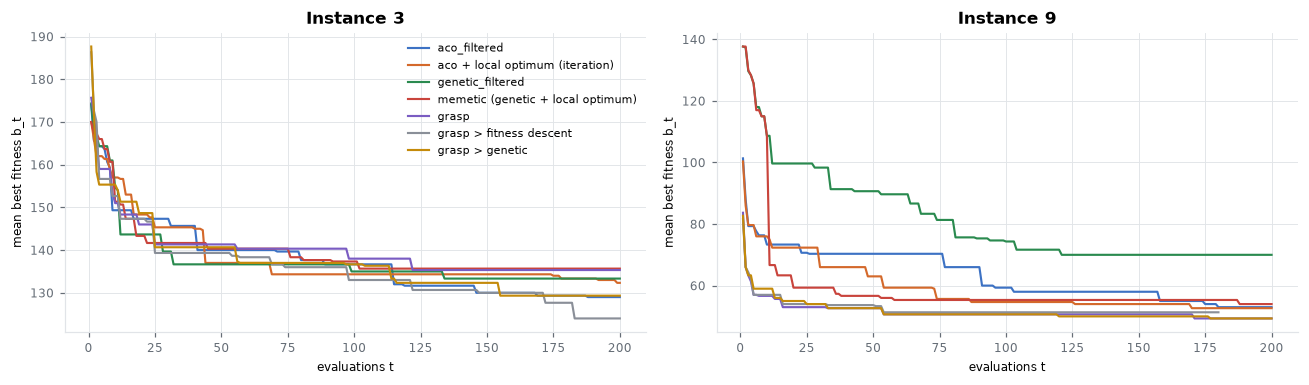

In [6]:
def plot_convergence(results, order):
    """Convergence moyenne b_t (moyenne sur les graines), une colonne par instance."""
    history = history_frame(results)
    instance_ids = sorted(history["instance_id"].unique())
    fig, axes = plt.subplots(1, len(instance_ids), figsize=(6 * len(instance_ids), 3.6), squeeze=False)
    for ax, instance_id in zip(axes[0], instance_ids):
        subset = history[history["instance_id"] == instance_id]
        for color, algorithm in zip(PALETTE, order):
            curves = subset[subset["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.4)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations t", fontsize=8)
        ax.set_ylabel("mean best fitness b_t", fontsize=8)
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()
    return fig


plot_convergence(components + hybrids, ORDER);

## Lecture de la démonstration

_Exécution du 23/11/2026 : instances 3 et 9, 3 graines, $B = 200$. Ce sont des exemples d'usage du système, pas une étude complète : les composants n'ont pas été réglés pour l'hybridation._

| Hybride | Instance 3 | Instance 9 | Lecture |
|---|---|---|---|
| algorithme mémétique (contre `genetic_filtered`) | 135,7 contre 133,3 | **54,0 contre 70,0** | l'optimum local de $C$ apporte à chaque enfant l'information locale qui manquait à l'algorithme génétique ; c'est utile là où $C$ est fiable (9), sans effet sur le plateau de $C$ (3) |
| `grasp > fitness descent` (contre `grasp`) | **124,0 contre 135,3** | 51,3 contre 49,3 | sur l'instance 3, $C$ ne distingue plus les placements, et la descente sur $f$ apporte l'information qui manque (130,0 → 124,0 pendant l'étape 2) ; sur l'instance 9, les 20 % retirés à GRASP coûtent un peu |
| `grasp > genetic` (contre `grasp`) | 129,3 contre 135,3 | 49,3 contre 49,3 | même mécanisme sur l'instance 3 : la sélection de l'algorithme génétique se fait sur $f$ (136,7 → 129,3 pendant l'étape 2) |
| `aco + local optimum` (contre `aco_filtered`) | 132,3 contre 129,0 | 52,7 contre 53,0 | aucun effet : les phéromones apprennent déjà les mêmes placements, et l'information de $C$ est déjà dans $\eta$ et dans le filtrage |

**Règle qui se dégage :**
- là où $C$ est fiable, une brique **sur $C$** rattrape la méthode à qui manque l'information locale (l'algorithme génétique) ;
- là où $C$ est sur un plateau (instance 3), seule une étape **sur $f$** (descente, ou sélection génétique) améliore GRASP.

**Point d'attention.** Une étape de relais qui s'arrête tôt ne consomme pas tout son budget : la descente sur $f$ ($R = 20$) s'est arrêtée après 20 à 27 évaluations sur les 40 prévues. Le reste est perdu si c'est la dernière étape. Il faut alors augmenter $R$, ou donner une part plus petite à l'étape.

## 3. Ajouter un hybride à la comparaison (notebook 99)

Un hybride s'ajoute comme n'importe quelle métaheuristique : une ligne dans `CONTENDERS`. Son cache et sa clé de paramètres fonctionnent de la même façon.

```python
from optimizer.hybrid import Hybrid

algorithm, params = Hybrid("grasp", **GRASP_BASE).then_improver("fitness_descent", share=0.2, patience=20).build()
CONTENDERS["grasp > fitness descent"] = {"family": "hybrid", "algorithm": algorithm, "params": params,
                                         "description": "GRASP (80 %) puis descente sur f (20 %)"}
```

## 4. Rendre une nouvelle métaheuristique compatible

Pour qu'une métaheuristique accepte les hooks et puisse servir d'étape de relais, il suffit de quatre lignes dans son `run` (exemple pour un recuit simulé) :

```python
from ..hybrid.hooks import improve_iteration, improve_solution, normalized

def run(problem, rng, t_start=..., ..., hooks=None, initial_mapping=None):
    hooks = normalized(hooks)                                   # 1. lire les hooks
    current = initial_mapping or ...                            # 2. point de départ (relais)
    current_cost = problem.fitness(current)
    while True:
        candidate = voisin(current, rng)
        candidate = improve_solution(problem, candidate, hooks, rng)        # 3. point « solution »
        cost = problem.fitness(candidate)
        if accepte(cost, current_cost, temperature):
            current, current_cost = candidate, cost
        current, current_cost = improve_iteration(problem, current, current_cost, hooks, rng)   # 4. point « itération »
```

L'exemple « recuit simulé avec une recherche locale à la fin de chaque itération, puis une recherche locale finale » s'écrit alors :

```python
Hybrid("simulated_annealing", ...).each_iteration("surrogate_local_optimum").then_improver("fitness_descent", share=0.1, patience=20)
```

Une nouvelle brique s'ajoute dans `optimizer/hybrid/improvers.py` : une fonction `(problem, mapping, cost, rng, **params) -> (mapping, cost)` enregistrée dans `IMPROVERS`.